Single cluster alogrithm for Ising model

2D Ising model (64x64) with the single cluster (Wolff) algorithm. I measure the spin correlation function at a few couplings J below the critical point and fit it to get the correlation length.

p = 0.5974758
Average magnetization (positive) = 0.78505
Average magnetization (negative) = -0.78637
Average magnetization = -0.00590


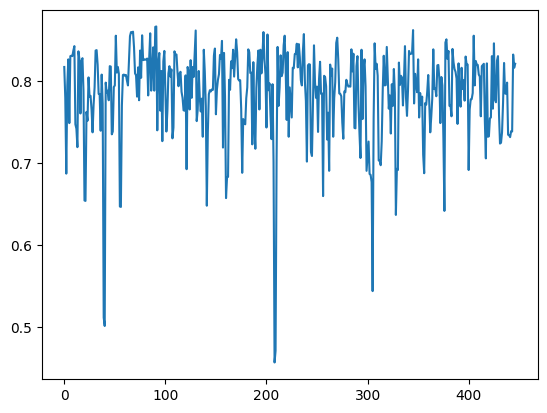

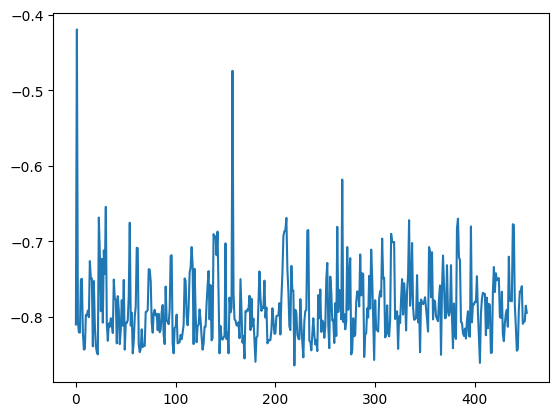

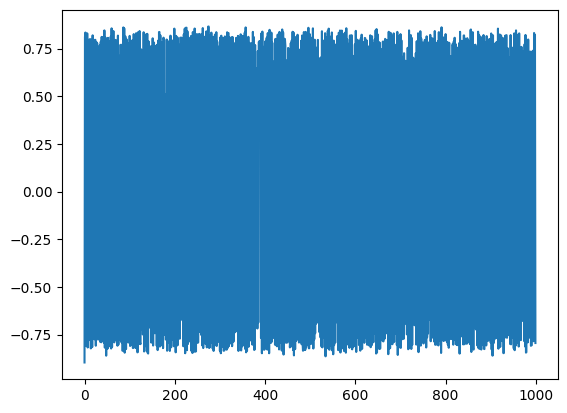

In [2]:
import numpy as np
from matplotlib import pyplot as plt

N = 64 
N2 = N*N
J = 0.455
p = 1 - np.exp(-2 * J)
print('p = {:.7f}'.format(p))
nsteps = 1000
ntherm = 100

sp = np.ones(N2)           #  spins
nn = np.zeros([N2,4])      #  nearest neighbors

M = np.zeros(nsteps)     #  magnetization

for i in np.arange(N2):    #  load nearest neighbors
    
    x = i % N
    y = np.floor(i / N)
    
    nn[i,0] = (x+1) % N + y * N
    nn[i,1] = (x-1) % N + y * N
    nn[i,2] = x + ((y+1) % N) * N
    nn[i,3] = x + ((y-1) % N) * N
    

def flip( i, s0):
    
    sp[i] = -s0
    for j in np.arange(4):
        ii = int(nn[i,j])
        if ( s0 == sp[ii] and np.random.rand() < p ):
            flip(ii, s0)
            
for n in np.arange(nsteps):
    
    i = int( N2 * np.random.rand())
    
    flip(i, sp[i])
    
    M[n] = np.mean(sp)
    
#  Find average magnetization in each of the two phases

Mt = M[ntherm:]
Mp = Mt[np.nonzero( Mt > 0 )]
Mn = Mt[np.nonzero( Mt < 0 )]

print('Average magnetization (positive) = {:.5f}'.format(np.mean(Mp)))
print('Average magnetization (negative) = {:.5f}'.format(np.mean(Mn)))
print('Average magnetization = {:.5f}'.format(np.mean(M[ntherm:])))
plt.plot(Mp)
plt.show()
plt.plot(Mn)    
plt.show()
plt.plot(M)    
plt.show()

All functions

In [5]:
from Sci_comp_helpers import acf,get_tau_int
# flip from orignal code
def flip(sp, i, s0, p):
    sp[i] = -s0
    for j in range(4):
        ii = int(nn[i, j])
        if (s0 == sp[ii]) and (np.random.rand() < p):
            flip(sp, ii, s0, p)
# compute equation 5 given a sppin configuration in sp
def sigma_z(sp, N):
    S = sp.reshape(N, N)
    Sigmax = S.mean(axis=0)  # over y -> function of x
    Sigmay = S.mean(axis=1)  # over x -> function of y
    corr = np.zeros(N, dtype=float)
    for z in range(N):
        cxxz = np.mean(Sigmax * np.roll(Sigmax, -z))
        cyyz = np.mean(Sigmay * np.roll(Sigmay, -z))
        corr[z] = 0.5 * (cxxz + cyyz)
    return corr
# num_updates cluster updates between measurements
def cluster_updates(sp, p, num_updates=10):
    
    for _ in range(num_updates):
        i = int(N2 * np.random.rand())
        flip(sp, i, sp[i], p)

# after thermalize, do n_meas of sigma(z) and cluster update between
def measure_corr(J_val, N, n_meas=200, updates=10, therm_steps=100):

    p = 1 - np.exp(-2.0 * J_val)
    sp = np.ones(N2)

    # Thermalize
    for _ in range(therm_steps):
        i = int(N2 * np.random.rand())
        flip(sp, i, sp[i], p)

    # Measurements
    meas = np.empty((n_meas, N))
    for k in range(n_meas):
        cluster_updates(sp, p, updates)
        meas[k, :] = sigma_z(sp, N)

    return meas

# ac correted stat anylysis
def stats_ac(meas, n_cut_max=200):

    M, A = meas.shape
    mean_sigma = meas.mean(axis=0)
    s = meas.std(axis=0, ddof=1)
    se_naive = s / np.sqrt(M)

    rho_full, _, _ = acf(meas, ncut=M-1) 

    ncut_used = np.empty(A)
    tau_int = np.empty(A)

    for a in range(A):
        r = rho_full[:, a] 
        # where rho first becomes negative          
        rho_zero = np.where(r <= 0.0)[0]     
        if rho_zero.size > 0:
            ncut_z = rho_zero[0] + 1         
        else:
            ncut_z = min(n_cut_max, M - 1)
        ncut_used[a] = ncut_z

        tau_int[a] = get_tau_int(rho_full,ncut=ncut_z)[a]

    se_ac = se_naive * np.sqrt((2.0 * tau_int))

    return {"meas": meas,
        "mean": mean_sigma,       
        "se_naive": se_naive,       
        "tau_int": tau_int,        
        "se_ac": se_ac, 
        "ncut_used": ncut_used,   
        "rho_full": rho_full        
    }



make correlataion measurements with stat analysis for J values

In [6]:
Js = [0.425, 0.43, 0.435]
results = {}    
n_meas = 200
ntherm = 100
updates = 10
for j in Js:
    n_meas = 200
    meas = measure_corr(J_val=j, N=N, n_meas=n_meas, updates=updates, therm_steps=ntherm)
    stats = stats_ac(meas, n_cut_max=n_meas)
    results[j] = stats

plot correlation for each (j,z) with ac corrected error bars

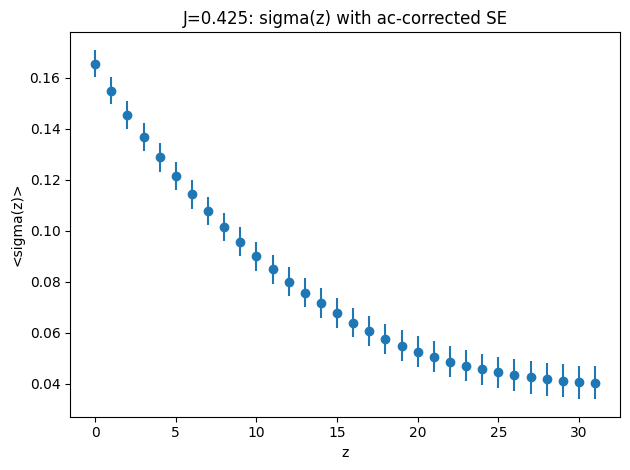

J=0.425  avg tau_int: 0.42662496475414 avg SE: 0.005911681558726473


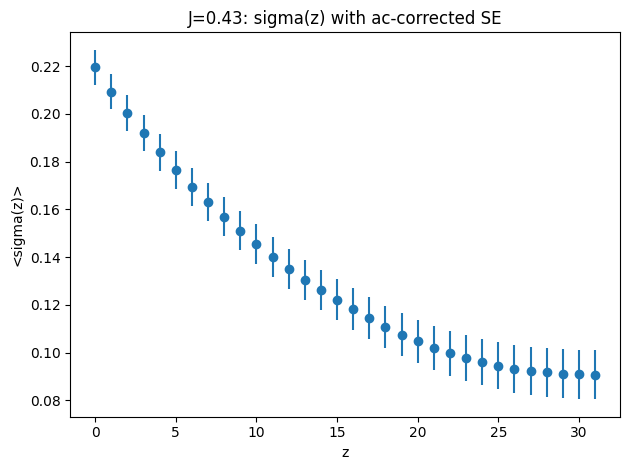

J=0.43  avg tau_int: 0.5283032466527574 avg SE: 0.008850934434546797


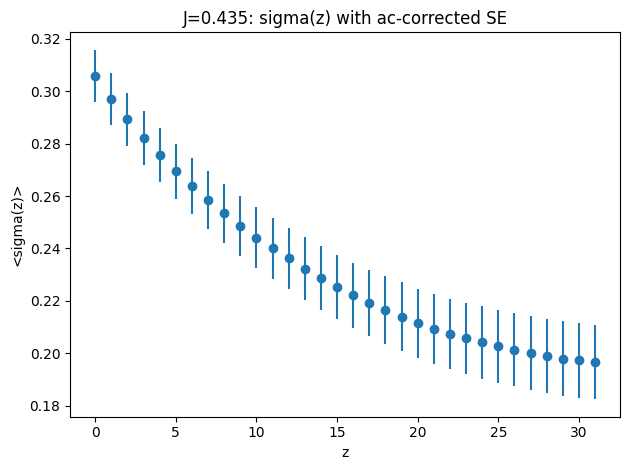

J=0.435  avg tau_int: 0.5422481249832443 avg SE: 0.01241028903036245


In [7]:
for j in Js:
    stats = results[j]
    z = np.arange(N)
    half = N//2

    plt.figure()
    plt.errorbar(z[:half], stats["mean"][:half], yerr=stats["se_ac"][:half],
                 fmt='o')
    # plt.yscale('log')
    
    plt.xlabel('z')
    plt.ylabel("<sigma(z)>")
    plt.title(f'J={j}: sigma(z) with ac-corrected SE')
    plt.tight_layout()
    plt.show()

    print(f"J={j}  avg tau_int: {np.mean(stats['tau_int'][1:half])} avg SE: {np.mean(stats['se_ac'][1:half])}")

plot some acfs

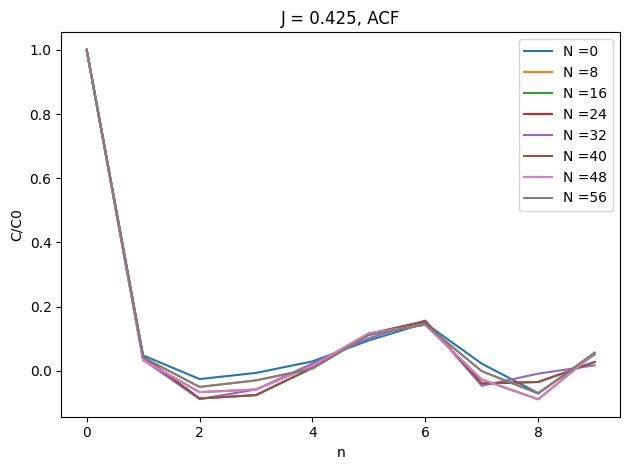

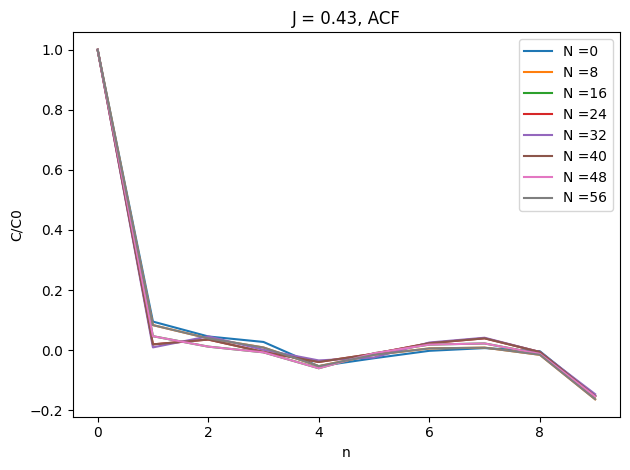

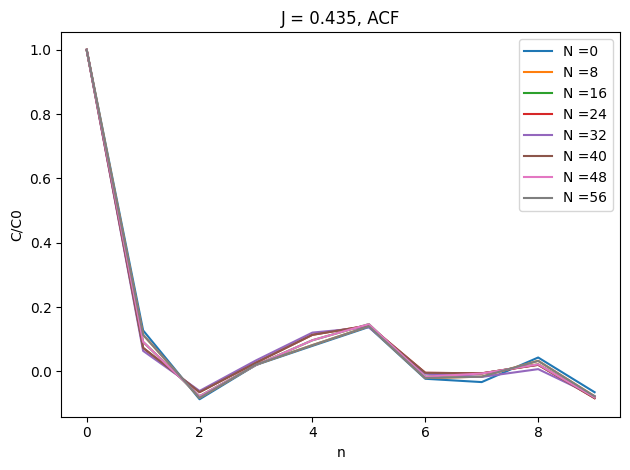

In [8]:
for j in Js:
  rho = results[j]["rho_full"]
  lags = np.arange(rho.shape[0])
  ncut = 10
  for k in range(0,N,8):
    plt.plot(lags[:ncut], rho[:ncut, k], label=f"N ={k}")
  plt.xlabel("n"); plt.ylabel("C/C0")
  plt.title(f"J = {j}, ACF")
  plt.legend()
  plt.tight_layout()
  plt.show()
  

curve fitting to find correlation length b)

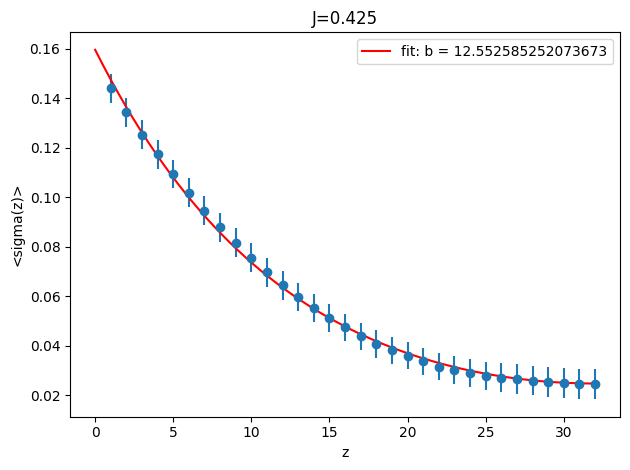

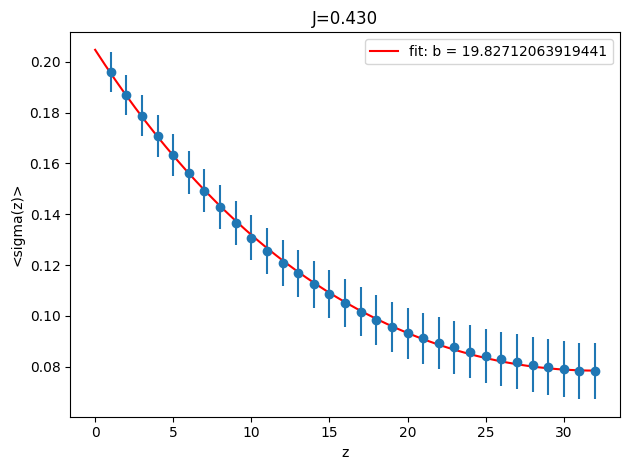

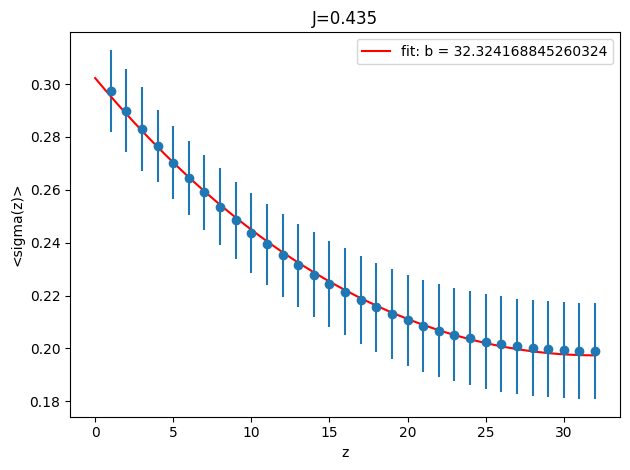


Estimated correlation lengths (b):
J = 0.425 ->  b = 12.552585252073673
J = 0.43 ->  b = 19.82712063919441
J = 0.435 ->  b = 32.324168845260324
We do see an increrase in b  as J -> J_c


In [ ]:
from scipy.optimize import curve_fit


def corr_model(z, a, b):
    return a * (np.exp(-z / b) + np.exp(-(N - z) / b))

b_vals = {}

for j in Js:
    stats = results[j]
    z = np.arange(N)
    y = stats["mean"]
    err = stats["se_ac"]

    mask = (z > 0) & (z <= N // 2)
    z_fit = z[mask]
    y_fit = y[mask]
    err_fit = err[mask]

    popt, pcov = curve_fit(corr_model,
                           z_fit, y_fit, sigma=err_fit)

    a_fit, b_fit = popt
    b_vals[j] = b_fit

    # Plot
    plt.figure()
    plt.errorbar(z_fit, y_fit, yerr=err_fit, fmt='o')
    zfine = np.linspace(0, N//2, 200)
    plt.plot(zfine, corr_model(zfine, a_fit,b_fit), 'r-',
             label=f'fit: b = {b_fit}')
    plt.xlabel('z')
    plt.ylabel("<sigma(z)>")
    plt.title(f'J={j:.3f}')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Print correlation lengths
print("\nEstimated correlation lengths (b):")
for j, b in b_vals.items():
    print(f"J = {j} ->  b = {b}")
print("We do see an increrase in b  as J -> J_c")